In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import os

import matplotlib.pyplot as plt
from astropy.visualization import make_lupton_rgb

In [2]:
datapath = 'data/first_test/' 

files = os.listdir(datapath)
images, filenames = [], []

for file in files:
    #if(not(file.startswith('DES2013-5248_r4575p01_g'))): continue
        
    hdul = fits.open(datapath + file)
    data = hdul[0].data
    images.append(data)
    filenames.append(file)
    
    hdul.close()

In [3]:
def plot_images(images, filenames):
    fig, axes = plt.subplots(ncols=len(images), figsize=(12, 3))

    for i, (ax, img) in enumerate(zip(axes, images)):
        title = filenames[i][24:-16]
        print(title)
        ax.set_title(title, fontsize=10)
        ax.imshow(img, origin='lower', cmap='gray')
        ax.axis('off')

    plt.show()
    

def plot_images(images, filenames, ncols=6):
    for start in range(0, len(images), ncols):
        chunk_imgs = images[start:start + ncols]
        chunk_names = filenames[start:start + ncols]

        fig, axes = plt.subplots(ncols=ncols, figsize=(12, 3))
        axes = np.atleast_1d(axes)

        for ax, img, name in zip(axes, chunk_imgs, chunk_names):
            title = name[24:-16]
            print(title)
            ax.set_title(title, fontsize=10)
            ax.imshow(img, origin='lower', cmap='gray')

        for ax in axes:
            ax.axis('off')

        plt.show()

18
extn1
nobkg-extn2
extn1
nobkg-extn3
nobkg-extn1
nobkg-extn3


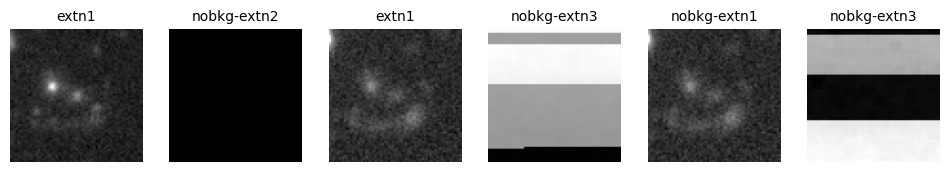

nobkg-extn2
extn1
extn2
nobkg-extn1
nobkg-extn2
extn3


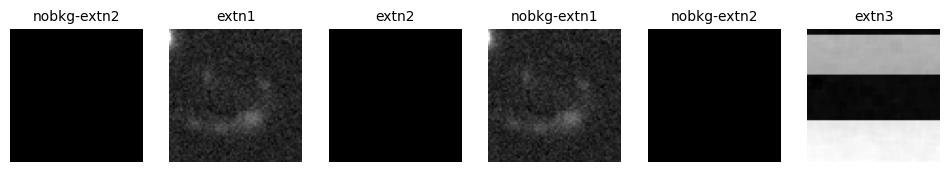

extn2
extn2
extn3
nobkg-extn1
extn3
nobkg-extn3


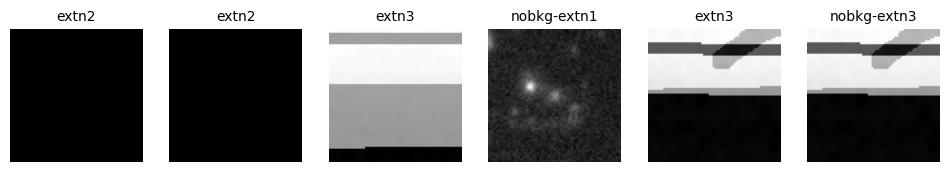

In [4]:
print(len(images))
plot_images(images, filenames)

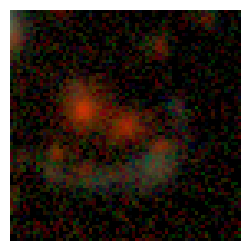

In [5]:
def plot_rgb_image(image, title=None):
    fig, ax = plt.subplots(figsize=(3, 3))
    rgb = make_lupton_rgb(image[2], image[1], image[0], Q=11., stretch=40.)
    ax.imshow(rgb, aspect='equal', origin='lower')
    ax.axis('off')

    if title is not None:
        ax.set_title(title)

    plt.show()
    plt.close()
        

for i in range(len(images)):
    file = filenames[i]
    if 'r_nobkg-extn1' in file: imager = images[i] #r_nobkg-extn1
    if 'g_nobkg-extn1' in file: imageg = images[i]
    if 'i_nobkg-extn1' in file: 
        imagei = images[i]
        image = [imageg, imager, imagei]

plot_rgb_image(image)